In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from scipy.signal import welch

In [3]:
# ============================================================
# 0. SETUP
# ============================================================
df = pd.read_csv("Project_Data_EE4C12_S&S_EMG.csv")

# Work on a copy so the original dataframe remains unchanged
data = df.copy()

emg_channels = [
    "channel1", "channel2", "channel3", "channel4",
    "channel5", "channel6", "channel7", "channel8"
]

In [8]:
# ------------------------------------------------------------
# IDENTIFY THE SERIES
# ------------------------------------------------------------

data = data.sort_index()

data["new_series"] = (
    data.groupby("label")["time"]
        .diff()
        .fillna(1)
        <= 0
)

# First row of every person must start a series
data["new_series"] = (
    data["new_series"]
    | data.groupby("label").cumcount().eq(0)
)

# Assign series number within each person
data["series"] = (
    data.groupby("label")["new_series"]
        .cumsum()
        .astype(int)
)

data.drop(columns="new_series", inplace=True)


series_per_person = data.groupby("label")["series"].nunique()

In [10]:
# ============================================================
# HAND GESTURES
# ============================================================

print("\n" + "=" * 70)
print("4. HAND GESTURES")
print("=" * 70)

gesture_counts = data["class"].value_counts().sort_index()

display(gesture_counts.to_frame("n_samples"))

# plt.figure(figsize=(10, 5))

# plt.bar(
#     gesture_counts.index.astype(str),
#     gesture_counts.values
# )

# plt.xlabel("Gesture")
# plt.ylabel("Number of samples")
# plt.title("Number of samples per gesture")

# plt.xticks(rotation=45)
# plt.tight_layout()
# plt.show()

person_gesture = pd.crosstab(
    data["label"],
    data["class"]
)

display(person_gesture)

# plt.figure(figsize=(12, 9))

# plt.imshow(
#     person_gesture,
#     aspect="auto"
# )

# plt.colorbar(label="Number of samples")

# plt.xlabel("Gesture")
# plt.ylabel("Person")
# plt.title("Number of samples per person and gesture")

# plt.xticks(
#     range(len(person_gesture.columns)),
#     person_gesture.columns,
#     rotation=45
# )

# plt.yticks(
#     range(len(person_gesture.index)),
#     person_gesture.index
# )

# plt.tight_layout()
# plt.show()



data["new_gesture"] = (
    data["class"].ne(data["class"].shift()) |
    data["series"].ne(data["series"].shift())
)

data["gesture_block"] = data["new_gesture"].cumsum()

gesture_durations = (
    data.groupby(["label", "series", "gesture_block", "class"])
        .size()
        .reset_index(name="n_samples")
)

print(gesture_durations.head())


# plt.figure(figsize=(10, 5))

# plt.hist(
#     gesture_durations["n_samples"],
#     bins=30,
#     edgecolor="black"
# )

# plt.xlabel("Aantal samples per gesture")
# plt.ylabel("Aantal gestures")
# plt.title("Verdeling van de duur van gestures")

# plt.tight_layout()
# plt.show()

gesture_durations["time_duration"] = (
    gesture_durations.groupby(["label", "series"])["n_samples"]
    .transform(lambda x: x)  # alleen voor behoud van structuur
)

gesture_time = (
    data.groupby(["label", "series", "gesture_block", "class"])
        .agg(
            start_time=("time", "first"),
            end_time=("time", "last"),
            n_samples=("time", "size")
        )
        .reset_index()
)

gesture_time["time_duration"] = (
    gesture_time["end_time"] - gesture_time["start_time"]
)

# plt.figure(figsize=(10, 5))

# plt.hist(
#     gesture_time["time_duration"],
#     bins=30,
#     edgecolor="black"
# )

# plt.xlabel("Duur van gesture (time)")
# plt.ylabel("Aantal gestures")
# plt.title("Verdeling van de duur van gestures")

# plt.tight_layout()
# plt.show()


# Previous and next class within the same series
group = data.groupby(["label", "series"])["class"]

prev_class = group.shift(1)
next_class = group.shift(-1)

# Start of a non-zero class sequence
start_nonzero = (
    (data["class"] != 0) &
    ((prev_class == 0) | prev_class.isna())
)

# End of a non-zero class sequence
end_nonzero = (
    (data["class"] != 0) &
    ((next_class == 0) | next_class.isna())
)

# End points of non-zero sequences
ends = data[end_nonzero].copy()
ends["next_class"] = next_class[end_nonzero]

# Non-zero sequences that are NOT followed by zero
invalid = ends[ends["next_class"] != 0]

print("Number of non-zero sequences:", len(ends))
print("Not followed by zero:", len(invalid))

if len(invalid) == 0:
    print("Every non-zero sequence is followed by a sequence of zeros.")
else:
    print("Not every non-zero sequence is followed by zeros.")
    display(
        invalid[["label", "series", "time", "class", "next_class"]]
    )



4. HAND GESTURES


,n_samples
class,
0,2725157
1,250055
2,243193
3,249494
4,251570
5,251733
6,253009
7,13696


class,0,1,2,3,4,5,6,7
label,,,,,,,,
1,78682,7311,6806,7329,6824,7075,7143,0
2,94654,7140,6777,6815,6812,6856,7372,0
3,67770,6443,6301,6486,6421,6278,6086,0
4,72578,6471,6598,6875,7193,7423,7060,0
5,68057,6506,6806,6874,6724,6098,6183,0
6,61128,5814,6243,6663,6688,7094,5989,0
7,82641,7523,7651,8383,8923,8414,9105,0
8,80264,6468,6537,5939,6027,6237,6476,0
9,90407,7083,6019,5838,5776,6050,6474,0


   label  series  gesture_block  class  n_samples
0      1       1              1      0       2287
1      1       1              2      1       2115
2      1       1              3      0       2022
3      1       1              4      2       1794
4      1       1              5      0       4316
Number of non-zero sequences: 872
Not followed by zero: 0
Every non-zero sequence is followed by a sequence of zeros.


In [11]:
channels = [f"channel{i}" for i in range(1, 9)]

groups = list(data.groupby("gesture_block", sort=False))

# Elke stroke is een array met shape (aantal_samples, 8)
strokes = [
    group[channels].to_numpy()
    for _, group in groups
]

# 2 x N matrix met [label, class] per stroke
labels_classes = np.array([
    [group["label"].iloc[0] for _, group in groups],
    [group["class"].iloc[0] for _, group in groups]
])

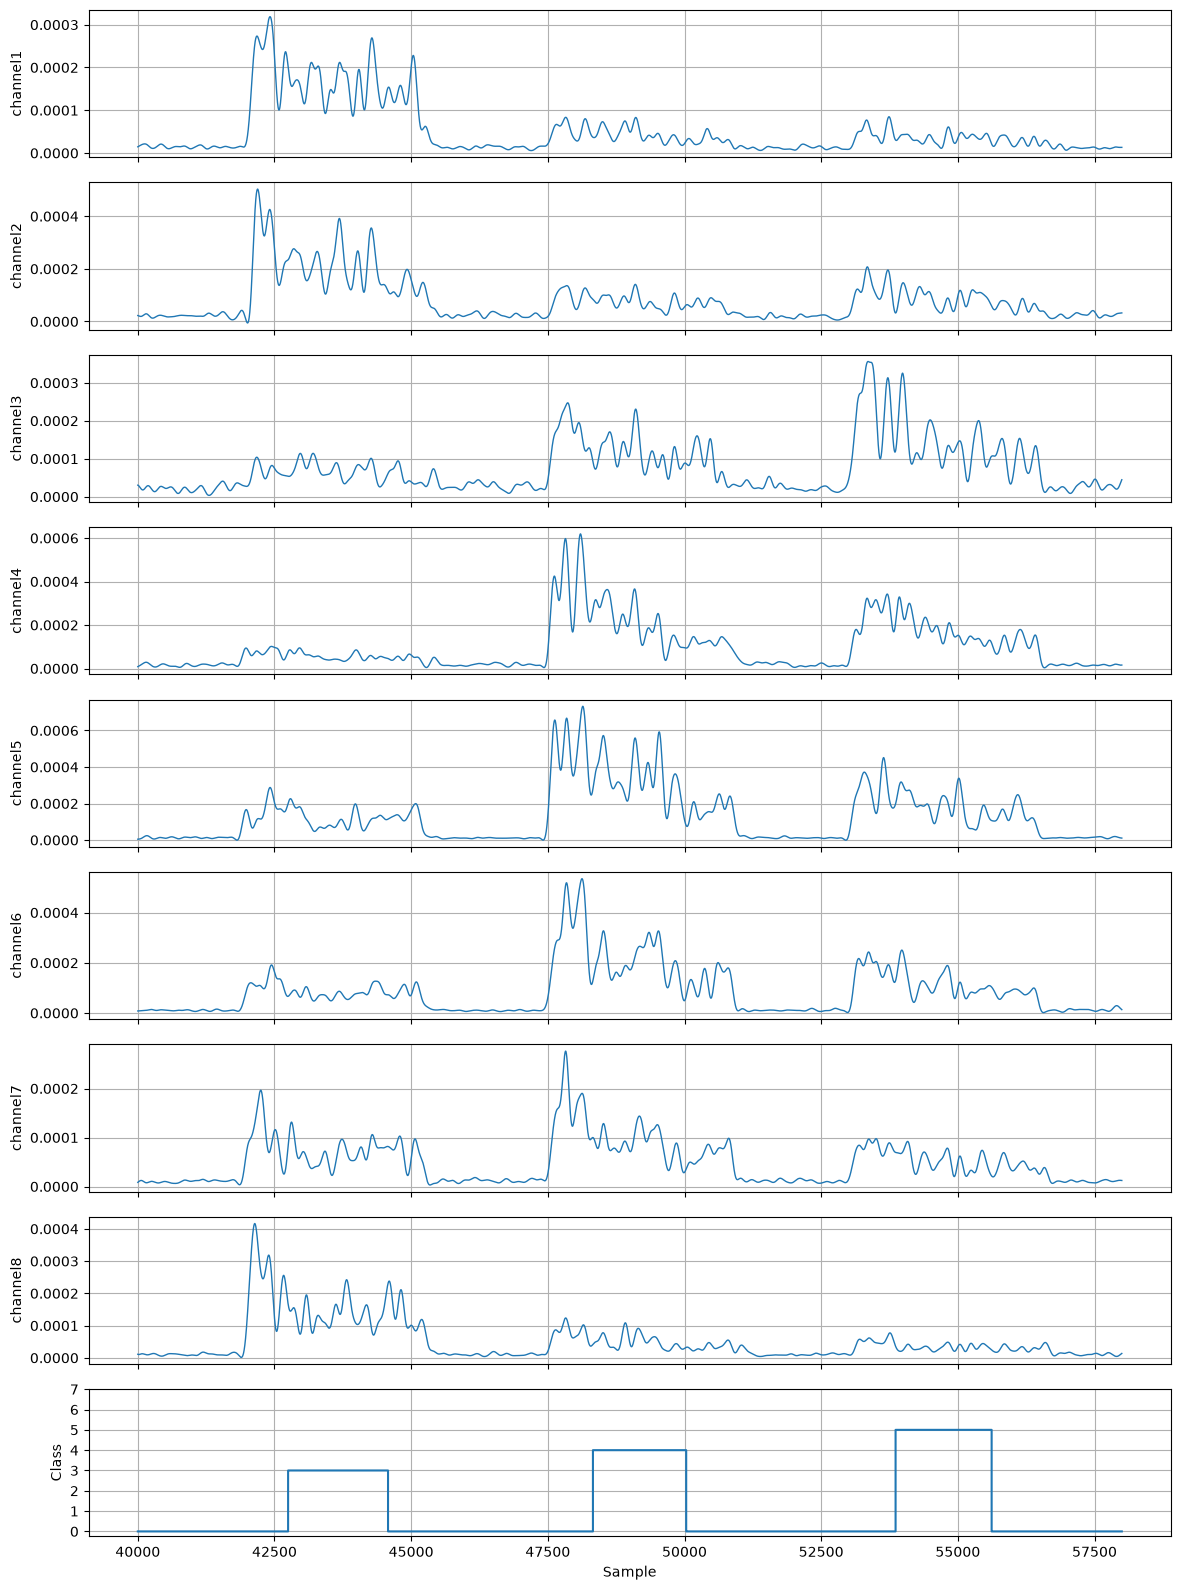

In [12]:
from scipy.signal import butter, filtfilt

channels = [f"channel{i}" for i in range(1, 9)]

start = 40000
end = 58000

# Set these parameters according to your EMG acquisition
fs = 1000          # Sampling frequency in Hz (change to your actual value)
cutoff = 5          # Envelope low-pass cutoff frequency in Hz
order = 4

# Design low-pass Butterworth filter
b, a = butter(order, cutoff / (fs / 2), btype="low")

# Calculate the envelope for each channel
envelopes = {}

for channel in channels:
    raw_emg = df[channel].to_numpy()

    # Full-wave rectification
    rectified_emg = np.abs(raw_emg)

    # Low-pass filtering to obtain the envelope
    envelopes[channel] = filtfilt(b, a, rectified_emg)

# Plot envelopes and class labels
fig, axes = plt.subplots(
    9, 1, figsize=(12, 16), sharex=True
)

for i, channel in enumerate(channels):
    axes[i].plot(
        df.index[start:end],
        envelopes[channel][start:end],
        linewidth=1
    )
    axes[i].set_ylabel(channel)
    axes[i].grid(True)

axes[8].step(
    df.index[start:end],
    df["class"].iloc[start:end],
    where="post"
)
axes[8].set_ylabel("Class")
axes[8].set_xlabel("Sample")
axes[8].set_yticks(range(8))
axes[8].grid(True)

plt.tight_layout()
plt.show()

In [14]:
"""
make empty df
for stroke in strokes: 
    calculate features
    put in dataframe
    
split based on pt number
"""

# Create an empty DataFrame
features_df = pd.DataFrame()

# Loop through every stroke
for i, stroke in enumerate(strokes):

    # Rectify the EMG signal
    rectified = np.abs(stroke)

    # Calculate features for each of the 8 channels
    rms = np.sqrt(np.mean(rectified**2, axis=0))
    std = np.std(rectified, axis=0)
    var = np.var(rectified, axis=0)
    max_val = np.max(rectified, axis=0)

    # Store features in a dictionary
    features = {}

    for ch in range(8):
        features[f"RMS_ch{ch+1}"] = rms[ch]
        features[f"STD_ch{ch+1}"] = std[ch]
        features[f"VAR_ch{ch+1}"] = var[ch]
        features[f"MAX_ch{ch+1}"] = max_val[ch]

    # Add corresponding label and class
    features["label"] = labels_classes[0, i]
    features["class"] = labels_classes[1, i]

    # Add stroke features as a new row
    features_df = pd.concat(
    [features_df, pd.DataFrame([features])],
    ignore_index=True
)

# Display results
print(features_df.shape)
display(features_df)

(1812, 34)


,RMS_ch1,STD_ch1,VAR_ch1,MAX_ch1,RMS_ch2,STD_ch2,VAR_ch2,MAX_ch2,RMS_ch3,STD_ch3,...,RMS_ch7,STD_ch7,VAR_ch7,MAX_ch7,RMS_ch8,STD_ch8,VAR_ch8,MAX_ch8,label,class
0,0.000015,0.000010,9.120722e-11,0.00006,0.000025,0.000017,2.993659e-10,0.00010,0.000027,0.000017,...,0.000014,0.000009,7.622353e-11,0.00004,0.000014,0.000009,7.715892e-11,0.00004,1,0
1,0.000016,0.000010,1.046765e-10,0.00004,0.000025,0.000016,2.498196e-10,0.00007,0.000028,0.000017,...,0.000014,0.000009,7.440864e-11,0.00004,0.000014,0.000009,8.131905e-11,0.00004,1,1
2,0.000202,0.000166,2.770679e-08,0.00088,0.000107,0.000082,6.723001e-09,0.00044,0.000144,0.000110,...,0.000330,0.000269,7.245440e-08,0.00109,0.000258,0.000213,4.547498e-08,0.00092,1,0
3,0.000254,0.000164,2.691809e-08,0.00111,0.000138,0.000085,7.210488e-09,0.00041,0.000221,0.000132,...,0.000255,0.000158,2.512021e-08,0.00070,0.000172,0.000110,1.215192e-08,0.00070,1,2
4,0.000212,0.000184,3.378487e-08,0.00127,0.000216,0.000192,3.694788e-08,0.00127,0.000189,0.000167,...,0.000199,0.000171,2.932971e-08,0.00127,0.000227,0.000189,3.570470e-08,0.00127,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1807,0.000055,0.000045,2.019815e-09,0.00031,0.000057,0.000044,1.965393e-09,0.00029,0.000051,0.000036,...,0.000030,0.000021,4.354771e-10,0.00016,0.000025,0.000016,2.676962e-10,0.00010,36,0
1808,0.000109,0.000074,5.474513e-09,0.00032,0.000109,0.000067,4.546173e-09,0.00029,0.000082,0.000055,...,0.000038,0.000026,6.711983e-10,0.00011,0.000032,0.000022,4.727116e-10,0.00010,36,5
1809,0.000055,0.000044,1.893740e-09,0.00021,0.000048,0.000035,1.236927e-09,0.00025,0.000048,0.000035,...,0.000054,0.000044,1.976352e-09,0.00036,0.000076,0.000065,4.281539e-09,0.00049,36,0
1810,0.000079,0.000064,4.136383e-09,0.00045,0.000028,0.000017,2.798247e-10,0.00008,0.000028,0.000017,...,0.000080,0.000048,2.279943e-09,0.00023,0.000085,0.000051,2.621818e-09,0.00031,36,6


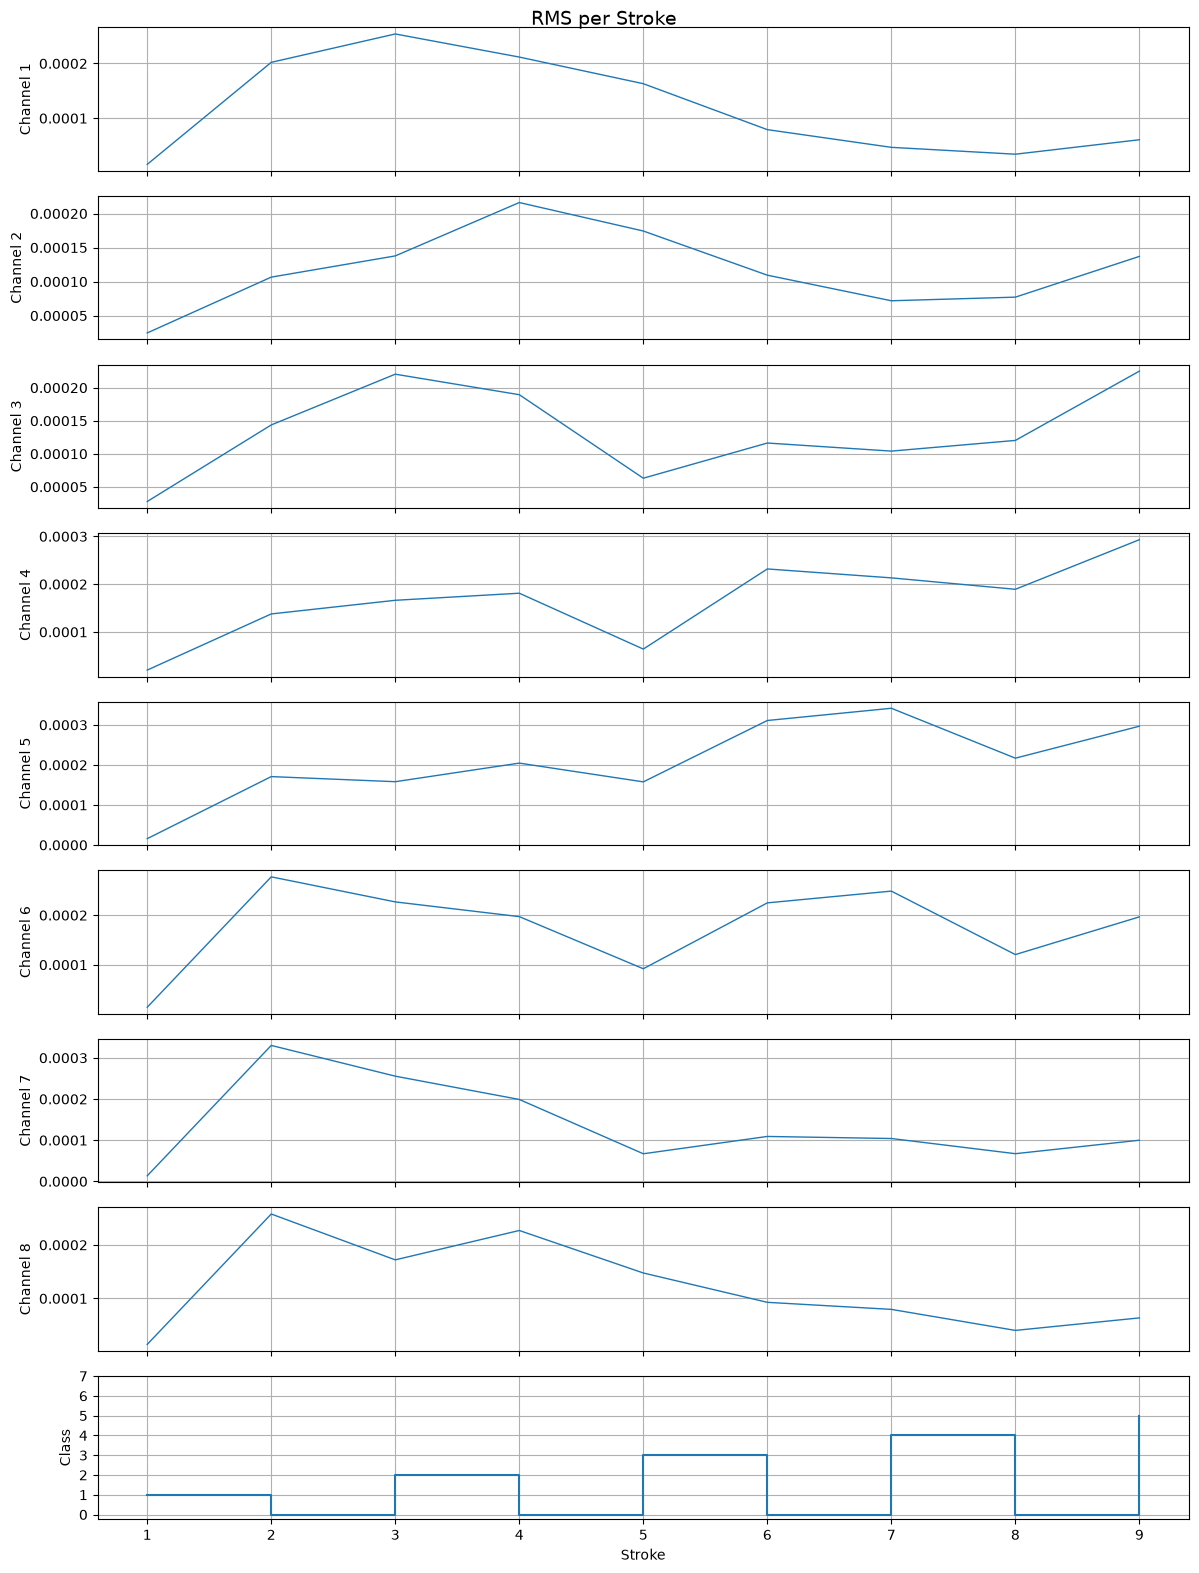

In [18]:
###

start_stroke = 1
end_stroke = 10

# Select strokes within the specified range
plot_df = features_df.iloc[start_stroke:end_stroke]

# Keep original stroke numbers
stroke_numbers = np.arange(start_stroke, start_stroke + len(plot_df))

###

fig, axes = plt.subplots(9, 1, figsize=(12, 16), sharex=True)

for ch in range(8):
    axes[ch].plot(
        stroke_numbers,
        plot_df[f"RMS_ch{ch+1}"],
        linewidth=1
    )
    axes[ch].set_ylabel(f"Channel {ch+1}")
    axes[ch].grid(True)

axes[8].step(
    stroke_numbers,
    plot_df["class"],
    where="post"
)
axes[8].set_ylabel("Class")
axes[8].set_xlabel("Stroke")
axes[8].set_yticks(sorted(features_df["class"].unique()))
axes[8].grid(True)

fig.suptitle("RMS per Stroke", fontsize=14)
plt.tight_layout()
plt.show()
